# AgriLens — what do narrow Tanager bands add?

**Evidence-first diagnostic notebook.** Uses uploaded *observed Tanager-derived spectral medians*; output is a red-edge representation comparison, **not validated crop-stress diagnosis or a Satellite 813 result**.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'data'/'spectral_signatures.csv').exists():
    ROOT=ROOT.parent
assert (ROOT/'data'/'spectral_signatures.csv').exists(), 'Run notebook from package root or notebooks directory'
sys.path.insert(0,str(ROOT/'scripts'))
from hsi_evidence import analyze_aggregates, pixelwise_experiment, verify_local_file
print('Working from:',ROOT)

Working from: /mnt/data/AgriLens_HSI_Evidence_Study


## 1. Reproduce the observed-median red-edge comparison

The input contains the median reflectance of 180 selected high-NDVI and 180 low-NDVI Tanager pixels. These are **relative NDVI quantiles, not ground-truth crop health classes**. Four wavelengths with no finite medians are excluded rather than imputed.

Clean wavelength rows: 357
Missing rows excluded: 4
Red-edge RMSE in reflectance (higher/lower NDVI group): {'higher_NDVI_quantile': np.float64(0.02064985895707167), 'lower_NDVI_quantile': np.float64(0.013464732484665693)}


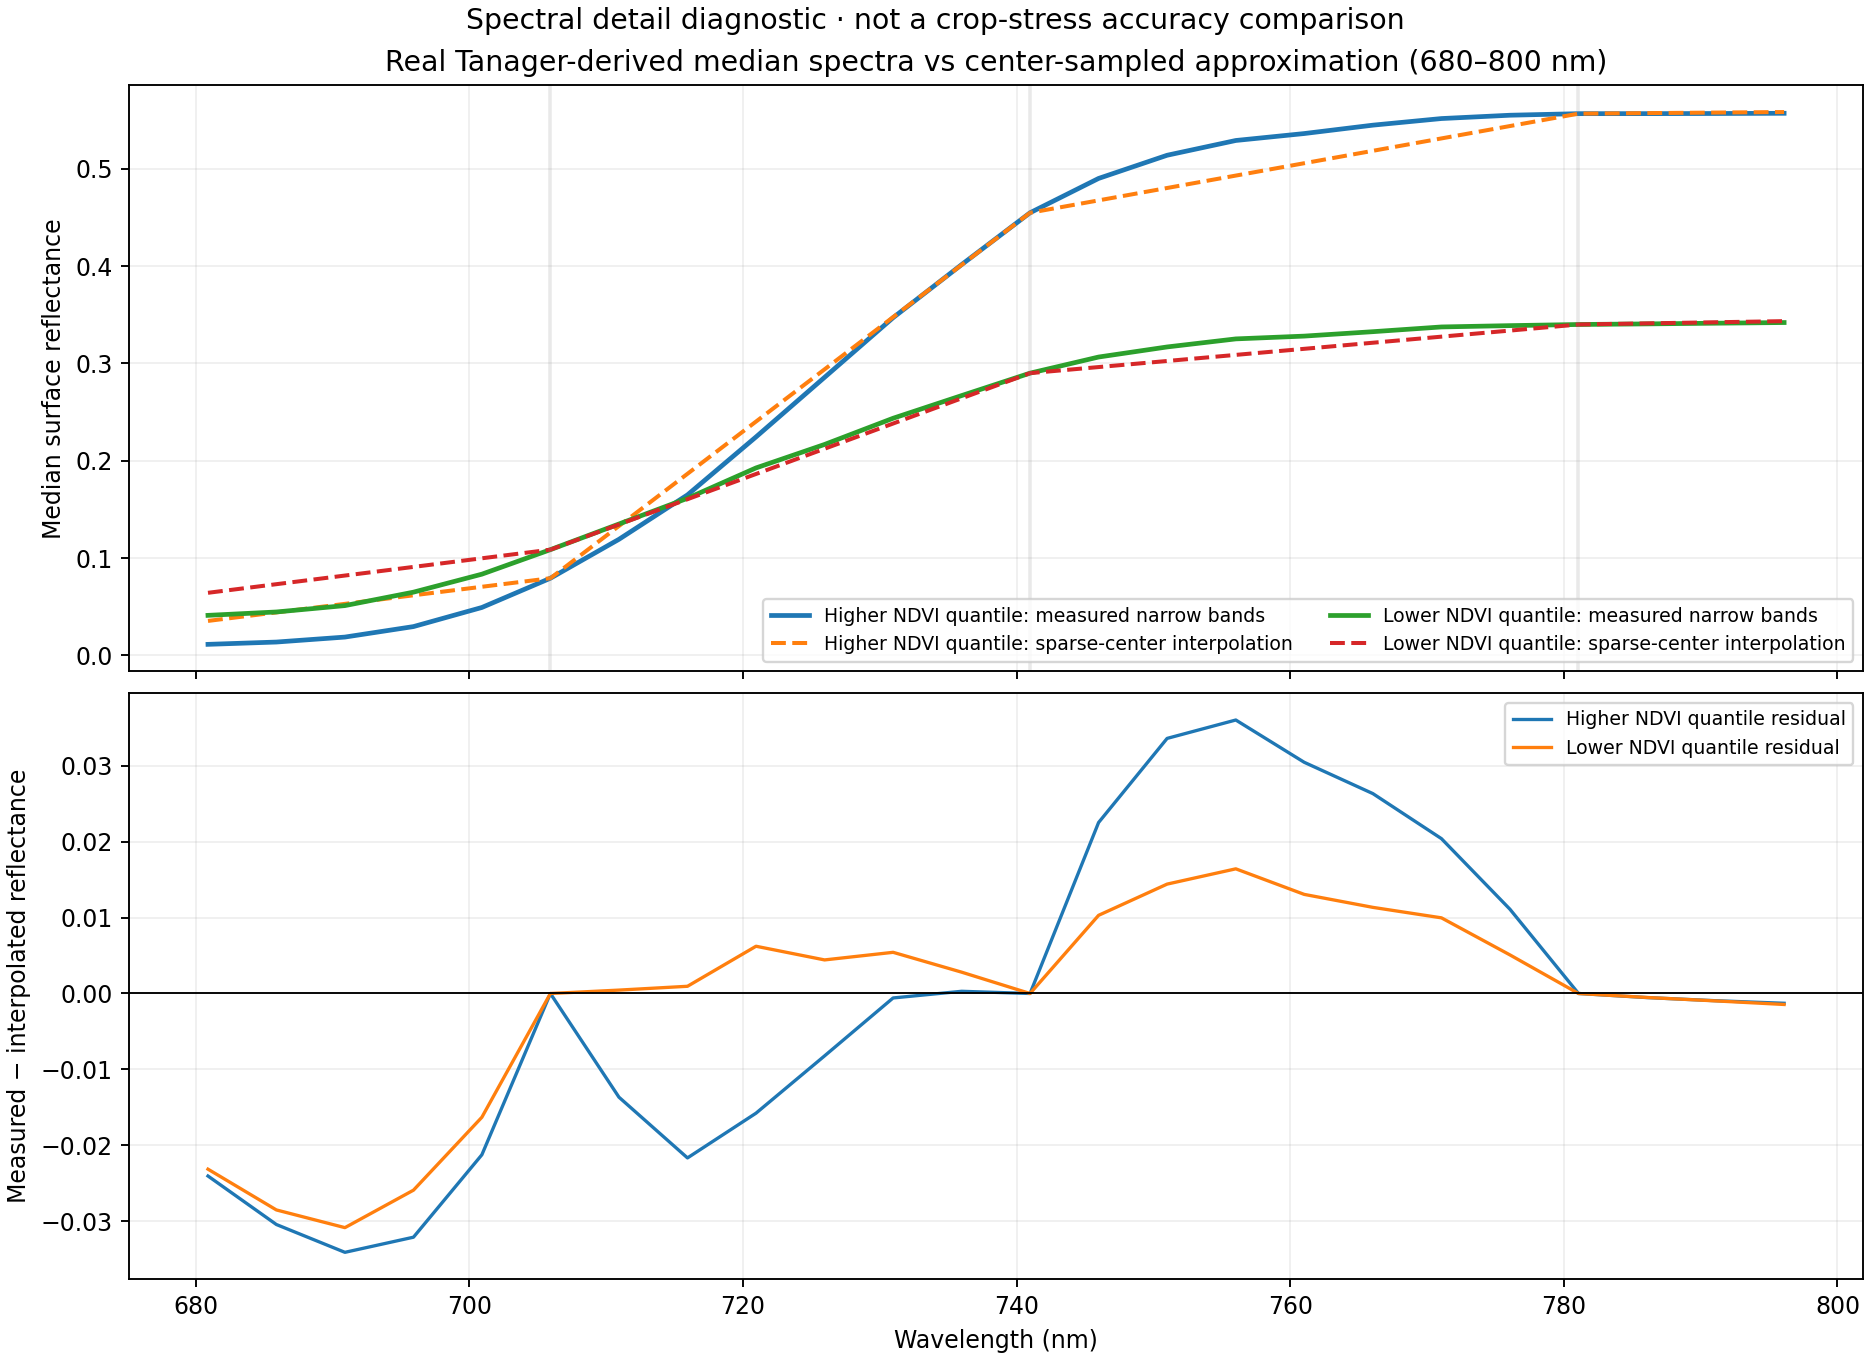

In [2]:
output=ROOT/'outputs'
result=analyze_aggregates(ROOT/'data/spectral_signatures.csv',ROOT/'data/processing_report.json',output)
print('Clean wavelength rows:',result['n_clean_spectral_rows'])
print('Missing rows excluded:',len(result['excluded_wavelengths_nm']))
print('Red-edge RMSE in reflectance (higher/lower NDVI group):', result['rededge_rmse_reflectance'])
display(Image(filename=str(output/'rededge_sparse_vs_dense.png')))

## 2. Optional: run genuine **per-pixel** Tanager analysis

You already downloaded `tanager_agriculture_new.h5` on your Windows computer. Set `H5_PATH` to the absolute path. If left as `None`, this cell skips HDF5 processing and the notebook still runs cleanly. The resulting error describes sparse-wavelength **spectral reconstruction**, not a comparison of crop-stress classifiers.

In [3]:
# Example on Windows:
# H5_PATH = Path(r'C:\Users\Lenovo\Downloads\AgriLens_Dust_Drought_v2\data\tanager_agriculture_new.h5')
H5_PATH = None
if H5_PATH is not None:
    H5_PATH=Path(H5_PATH)
    assert H5_PATH.is_file(),f'HDF5 missing: {H5_PATH}'
    idcheck=verify_local_file(H5_PATH,ROOT/'data/processing_report.json',output)
    print('Matches reported shape:',idcheck['matches_uploaded_report_shape'])
    print('Official publisher SHA-256 authenticated:',idcheck['authenticated_against_publisher_hash'])
    pixel_result=pixelwise_experiment(H5_PATH,output,stride=8,max_pixels=1500,min_ndvi=.3)
    print('Number of real pixel samples:',pixel_result['n_sampled_pixels'])
    print('Median reconstruction RMSE:',pixel_result['rmse_reflectance_median'])
    display(Image(filename=str(output/'pixelwise_spectral_reconstruction.png')))
else:
    print('Local HDF5 not provided to this notebook run; real per-pixel analysis is pending.')

Local HDF5 not provided to this notebook run; real per-pixel analysis is pending.


## 3. Interpretation and next requirements

- **Demonstrated:** real Tanager-derived median reflectance exhibits red-edge details not recovered by linear interpolation of six sparse center-wavelength samples.
- **Not demonstrated:** better crop-stress classification, valid dust/drought diagnoses, or processing of Satellite 813 imagery.
- **Fair next experiment:** use independent crop/soil reference labels, compare the same fields and spatially independent test set, and simulate multispectral band responses with real spectral response functions rather than sampling centers.
- **Sensor access:** do not claim Satellite 813 processing until an authorized actual 813 product has been loaded and validated.

See `docs/VALIDATION_AND_813_PROTOCOL.md` and the package README.